## 1. Import dan konfigurasi

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn, xgboost

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report,
                             precision_recall_curve, roc_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

sys.path.insert(0, str(Path.cwd()))
from url_features import buat_matriks_fitur, normalisasi_batch, NAMA_FITUR

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
WARNA = {"legitimate": "#1f77b4", "phishing": "#d95f02"}
SEED = 42
FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
Path("models").mkdir(exist_ok=True)

## 2. Memuat data olahan

In [2]:
df = pd.read_parquet("data/data_olahan.parquet")
X = df[NAMA_FITUR]
y = df["label"].values
print(df.shape, "| phishing: %.1f%%" % (100*y.mean()))

(497029, 46) | phishing: 30.4%


## 3. Pembagian data: latih / validasi / uji **per grup domain**
Soal UAS: *"Cegah data yang sama atau sangat mirip masuk ke bagian berbeda."*
Di Notebook 1 kita melihat satu domain bisa punya ribuan URL. Karena itu kita memakai `StratifiedGroupKFold`: semua URL dari **satu domain terdaftar** selalu berada di **satu bagian saja**, sambil menjaga proporsi kelas tetap mirip.

7 lipatan → 1 lipatan untuk uji (~14%), 1 untuk validasi (~14%), 5 untuk latih (~71%).

In [3]:
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
lipatan = [idx for _, idx in sgkf.split(X, y, groups=df["domain"])]
idx_te, idx_va = lipatan[0], lipatan[1]
idx_tr = np.concatenate(lipatan[2:])

X_tr, y_tr = X.iloc[idx_tr], y[idx_tr]
X_va, y_va = X.iloc[idx_va], y[idx_va]
X_te, y_te = X.iloc[idx_te], y[idx_te]
u_tr, u_va, u_te = df["url_norm"].iloc[idx_tr], df["url_norm"].iloc[idx_va], df["url_norm"].iloc[idx_te]

# --- Verifikasi anti-bocor ---
d_tr, d_va, d_te = (set(df["domain"].iloc[i]) for i in (idx_tr, idx_va, idx_te))
print("Domain yang sama di latih & uji      :", len(d_tr & d_te))
print("Domain yang sama di latih & validasi :", len(d_tr & d_va))
print("Domain yang sama di validasi & uji   :", len(d_va & d_te))
assert not (d_tr & d_te) and not (d_tr & d_va) and not (d_va & d_te)

ringkas = pd.DataFrame({
    "baris": [len(idx_tr), len(idx_va), len(idx_te)],
    "% phishing": [100*y_tr.mean(), 100*y_va.mean(), 100*y_te.mean()],
    "domain unik": [len(d_tr), len(d_va), len(d_te)]}, index=["latih", "validasi", "uji"]).round(1)
display(ringkas)
display(pd.crosstab(df["sumber"].iloc[idx_te], df["label_teks"].iloc[idx_te]).rename_axis("Sebaran data uji per sumber"))

Domain yang sama di latih & uji      : 0
Domain yang sama di latih & validasi : 0
Domain yang sama di validasi & uji   : 0


,baris,% phishing,domain unik
latih,371793,30.5,101700
validasi,69603,29.4,20342
uji,55633,31.3,20325


label_teks,legitimate,phishing
Sebaran data uji per sumber,,
D1_URL_dataset,38226,14254
D2_Phishing_URLs,0,3153


## 4. Fungsi evaluasi
Metrik utama adalah **recall, precision, dan F1 untuk kelas phishing**, plus PR-AUC (tidak bergantung threshold). *Accuracy* tetap dilaporkan karena diminta soal, tetapi tidak dijadikan patokan karena kelas tidak seimbang.

In [4]:
def evaluasi(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, proba),
            "pr_auc": average_precision_score(y_true, proba)}

hasil_val, proba_val, model_terlatih, waktu_latih = {}, {}, {}, {}

def latih_dan_nilai(nama, model, Xtr, Xva, fit_kwargs=None):
    t0 = time.time()
    model.fit(Xtr, y_tr, **(fit_kwargs or {}))
    waktu_latih[nama] = time.time() - t0
    p = model.predict_proba(Xva)[:, 1]
    model_terlatih[nama], proba_val[nama] = model, p
    hasil_val[nama] = evaluasi(y_va, p)
    print(f"{nama:<28} selesai dalam {waktu_latih[nama]:.0f} dtk | F1={hasil_val[nama]['f1']:.4f} PR-AUC={hasil_val[nama]['pr_auc']:.4f}")

## 5. Melatih model
**Penanganan ketidakseimbangan kelas** dilakukan hanya pada data latih lewat pembobotan (`class_weight` / `scale_pos_weight`). Data validasi dan uji dibiarkan dalam proporsi aslinya.

**Preprocessing difit hanya di data latih:** `StandardScaler` (dan `TfidfVectorizer`) berada di dalam `Pipeline`, sehingga `fit()` hanya melihat data latih.

### Model 1 — Logistic Regression (baseline, mudah dijelaskan)
`log1p` meredam fitur berekor panjang (mis. panjang URL), lalu `StandardScaler` menyamakan skala.

In [5]:
lr = Pipeline([("log", FunctionTransformer(np.log1p)),
               ("skala", StandardScaler()),
               ("clf", LogisticRegression(class_weight="balanced", max_iter=500, random_state=SEED))])
latih_dan_nilai("LogReg (40 fitur)", lr, X_tr, X_va)

LogReg (40 fitur)            selesai dalam 1 dtk | F1=0.6821 PR-AUC=0.8118


### Model 2 — Random Forest
Mampu menangkap hubungan non-linear dan interaksi antar fitur tanpa scaling. `n_estimators` dan `min_samples_leaf` dipilih moderat agar cepat dan tidak overfit.

In [6]:
rf = RandomForestClassifier(n_estimators=150, min_samples_leaf=3, max_features="sqrt", max_samples=0.6,
                            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
latih_dan_nilai("RandomForest (40 fitur)", rf, X_tr, X_va)

RandomForest (40 fitur)      selesai dalam 8 dtk | F1=0.8348 PR-AUC=0.9072


### Model 3 — XGBoost
*Gradient boosting* biasanya terbaik pada data tabular. Ia dipakai juga pada paper rujukan. `scale_pos_weight` menyeimbangkan kelas, dan *early stopping* memakai data **validasi** (bukan uji) untuk menghentikan pohon tambahan yang tidak membantu.

In [7]:
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
xgb = XGBClassifier(n_estimators=600, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                    min_child_weight=3, scale_pos_weight=spw, tree_method="hist", eval_metric="aucpr",
                    early_stopping_rounds=30, n_jobs=-1, random_state=SEED)
latih_dan_nilai("XGBoost (40 fitur)", xgb, X_tr, X_va, fit_kwargs=dict(eval_set=[(X_va, y_va)], verbose=False))
print("Jumlah pohon terpakai:", xgb.best_iteration + 1)

XGBoost (40 fitur)           selesai dalam 7 dtk | F1=0.8446 PR-AUC=0.9342
Jumlah pohon terpakai: 372


### Model 4 — TF-IDF karakter n-gram + Logistic Regression (model teks)
Pendekatan berbeda: URL diperlakukan sebagai **teks**. Potongan 3–5 karakter (mis. `logi`, `.php`, `-verif`) menjadi fitur otomatis, tanpa rancangan manual. Hasil model ini membantu kita menilai apakah 40 fitur buatan sendiri sudah cukup.

In [8]:
tfidf = TfidfVectorizer(analyzer="char", ngram_range=(3, 5), min_df=10, max_features=300_000,
                        sublinear_tf=True, dtype=np.float32, lowercase=True)
t0 = time.time()
M_tr = tfidf.fit_transform(u_tr)          # fit HANYA pada data latih
M_va, M_te = tfidf.transform(u_va), tfidf.transform(u_te)
print(f"TF-IDF: {M_tr.shape} | {time.time()-t0:.0f} dtk")

lr_txt = LogisticRegression(class_weight="balanced", solver="liblinear", C=3.0, max_iter=200, random_state=SEED)
latih_dan_nilai("TFIDF-char + LogReg", lr_txt, M_tr, M_va)

TF-IDF: (371793, 300000) | 45 dtk
TFIDF-char + LogReg          selesai dalam 14 dtk | F1=0.9034 PR-AUC=0.9752


## 6. Perbandingan model (data validasi, threshold 0,5)

,accuracy,precision,recall,f1,roc_auc,pr_auc,waktu_latih_dtk
TFIDF-char + LogReg,0.9410,0.8712,0.9381,0.9034,0.9870,0.9752,14.0
XGBoost (40 fitur),0.9052,0.8158,0.8754,0.8446,0.9610,0.9342,7.0
RandomForest (40 fitur),0.8993,0.8070,0.8645,0.8348,0.9489,0.9072,8.0
LogReg (40 fitur),0.7843,0.6022,0.7864,0.6821,0.8808,0.8118,1.0


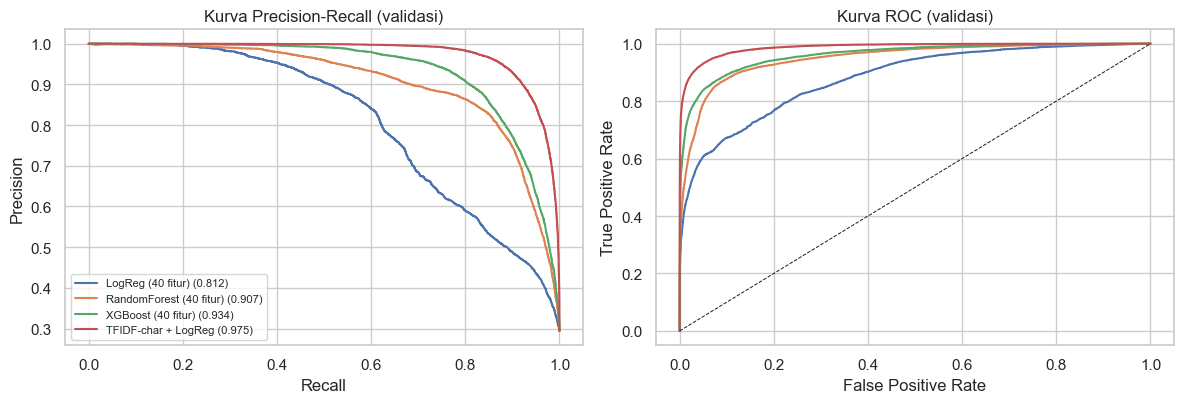

In [9]:
tab = pd.DataFrame(hasil_val).T
tab["waktu_latih_dtk"] = pd.Series(waktu_latih).round(0)
tab = tab.sort_values("pr_auc", ascending=False)
display(tab.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for nama, p in proba_val.items():
    pr, rc, _ = precision_recall_curve(y_va, p); ax[0].plot(rc, pr, label=f"{nama} ({hasil_val[nama]['pr_auc']:.3f})")
    fp, tp, _ = roc_curve(y_va, p); ax[1].plot(fp, tp, label=nama)
ax[0].set(xlabel="Recall", ylabel="Precision", title="Kurva Precision-Recall (validasi)"); ax[0].legend(fontsize=8)
ax[1].plot([0, 1], [0, 1], "k--", lw=.7); ax[1].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="Kurva ROC (validasi)")
plt.tight_layout(); plt.savefig(FIG/"06_perbandingan_model.png", dpi=150); plt.show()

### Cara membaca tabel
- **PR-AUC** dipakai sebagai kriteria pemilihan karena tidak bergantung pada threshold dan peka terhadap kelas minoritas (phishing).
- Bandingkan juga **recall** dan **precision** pada threshold 0,5, bukan hanya akurasi.
- Pertimbangkan **waktu latih** dan **kemudahan penjelasan** saat presentasi, bukan hanya angka tertinggi.

## 7. Memilih model dan threshold (hanya dari data validasi)
Dua jenis kesalahan punya dampak berbeda:
| Kesalahan | Arti | Dampak |
|---|---|---|
| **False Negative (FN)** | Phishing dianggap aman | Pengguna membuka situs palsu → kredensial/uang bocor (**paling berbahaya**) |
| **False Positive (FP)** | Situs aman dianggap phishing | Pengguna terganggu dan kepercayaan pada aplikasi turun (alert fatigue) |

Karena FN lebih berbahaya, kita menetapkan target **recall phishing ≥ 95%** pada data validasi, lalu memilih threshold tertinggi yang mencapainya (agar FP sekecil mungkin).

In [10]:
TARGET_RECALL = 0.95
nama_terbaik = max(hasil_val, key=lambda k: hasil_val[k]["pr_auc"])
print("Model terbaik (PR-AUC validasi):", nama_terbaik)

def pilih_threshold(y_true, proba, target_recall):
    pr, rc, th = precision_recall_curve(y_true, proba)
    ok = np.where(rc[:-1] >= target_recall)[0]
    i = ok[-1]                      # threshold tertinggi yang masih memenuhi target recall
    return float(th[i]), float(pr[i]), float(rc[i])

thr_recall, pr_at, rc_at = pilih_threshold(y_va, proba_val[nama_terbaik], TARGET_RECALL)
f1s = [f1_score(y_va, proba_val[nama_terbaik] >= t) for t in np.linspace(.05, .95, 91)]
thr_f1 = np.linspace(.05, .95, 91)[int(np.argmax(f1s))]
print(f"Threshold target-recall {TARGET_RECALL:.0%}: {thr_recall:.3f} (precision {pr_at:.3f}, recall {rc_at:.3f})")
print(f"Threshold F1 maksimum        : {thr_f1:.3f} (F1 {max(f1s):.3f})")
THRESHOLD = thr_recall

Model terbaik (PR-AUC validasi): TFIDF-char + LogReg
Threshold target-recall 95%: 0.443 (precision 0.846, recall 0.950)
Threshold F1 maksimum        : 0.660 (F1 0.915)


## 8. Evaluasi akhir pada data uji (dibuka satu kali)

Model: TFIDF-char + LogReg | threshold = 0.443


,data uji
accuracy,0.9538
precision,0.9067
recall,0.9500
f1,0.9279
roc_auc,0.9897
pr_auc,0.9824


              precision    recall  f1-score   support

  legitimate     0.9767    0.9555    0.9660     38226
    phishing     0.9067    0.9500    0.9279     17407

    accuracy                         0.9538     55633
   macro avg     0.9417    0.9528    0.9469     55633
weighted avg     0.9548    0.9538    0.9541     55633

TN=36,525  FP=1,701  FN=870  TP=16,537
-> dari 1.000 situs aman, 44.5 salah ditandai phishing; dari 1.000 phishing, 50.0 lolos.


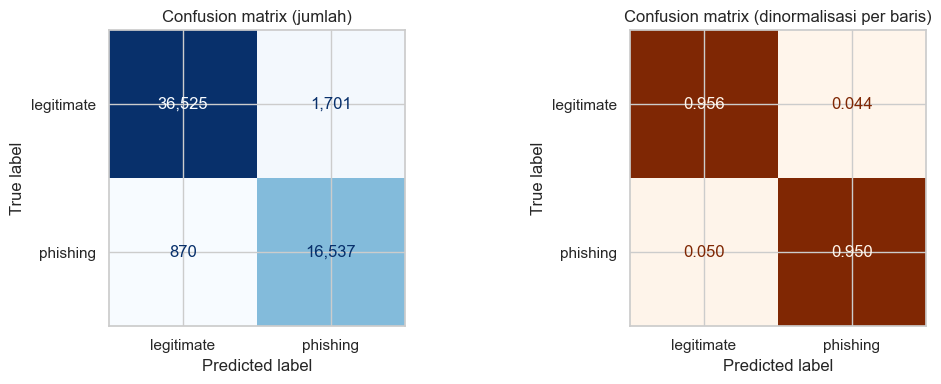

In [11]:
def proba_uji(nama):
    if nama.startswith("TFIDF"): return model_terlatih[nama].predict_proba(M_te)[:, 1]
    return model_terlatih[nama].predict_proba(X_te)[:, 1]

p_te = proba_uji(nama_terbaik)
pred_te = (p_te >= THRESHOLD).astype(int)
hasil_te = evaluasi(y_te, p_te, THRESHOLD)
print(f"Model: {nama_terbaik} | threshold = {THRESHOLD:.3f}")
display(pd.Series(hasil_te).round(4).to_frame("data uji"))
print(classification_report(y_te, pred_te, target_names=["legitimate", "phishing"], digits=4))

cm = confusion_matrix(y_te, pred_te)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")
print(f"-> dari 1.000 situs aman, {1000*fp/(tn+fp):.1f} salah ditandai phishing; dari 1.000 phishing, {1000*fn/(fn+tp):.1f} lolos.")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(cm, display_labels=["legitimate", "phishing"]).plot(ax=ax[0], cmap="Blues", values_format=",d", colorbar=False)
ax[0].set_title("Confusion matrix (jumlah)")
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te, normalize="true"), display_labels=["legitimate", "phishing"]).plot(ax=ax[1], cmap="Oranges", values_format=".3f", colorbar=False)
ax[1].set_title("Confusion matrix (dinormalisasi per baris)")
plt.tight_layout(); plt.savefig(FIG/"07_confusion_matrix_uji.png", dpi=150); plt.show()

In [12]:
# Semua model pada data uji memakai threshold masing-masing dari validasi
baris = {}
for nama in model_terlatih:
    t_m, _, _ = pilih_threshold(y_va, proba_val[nama], TARGET_RECALL)
    baris[nama] = {**evaluasi(y_te, proba_uji(nama), t_m), "threshold": t_m}
tabel_uji = pd.DataFrame(baris).T.sort_values("pr_auc", ascending=False)
display(tabel_uji.round(4))
tabel_uji.round(4).to_csv("reports/hasil_model_uji.csv")

,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
TFIDF-char + LogReg,0.9538,0.9067,0.9500,0.9279,0.9897,0.9824,0.4429
XGBoost (40 fitur),0.8223,0.6555,0.9108,0.7623,0.9431,0.9165,0.2163
RandomForest (40 fitur),0.8011,0.6252,0.9100,0.7412,0.9397,0.8991,0.2447
LogReg (40 fitur),0.6418,0.4648,0.9557,0.6254,0.9041,0.8508,0.1899


### 8.1 Hasil per sumber data
Dataset 1 (phishing lama + legitimate) dan Dataset 2 (phishing modern) berbeda karakter. Rata-rata keseluruhan bisa menutupi performa buruk pada salah satunya.

In [13]:
sumber_te = df["sumber"].iloc[idx_te].values
rows = []
for s in np.unique(sumber_te):
    m = sumber_te == s
    if y_te[m].min() == 0:   # ada kedua kelas
        rows.append({"sumber": s, "n": m.sum(), "recall_phishing": recall_score(y_te[m], pred_te[m]),
                     "precision_phishing": precision_score(y_te[m], pred_te[m]), "FPR_legit": ((pred_te[m] == 1) & (y_te[m] == 0)).sum() / (y_te[m] == 0).sum()})
    else:                    # hanya phishing
        rows.append({"sumber": s, "n": m.sum(), "recall_phishing": recall_score(y_te[m], pred_te[m]),
                     "precision_phishing": np.nan, "FPR_legit": np.nan})
display(pd.DataFrame(rows).round(4))

,sumber,n,recall_phishing,precision_phishing,FPR_legit
0,D1_URL_dataset,52480,0.9507,0.8885,0.0445
1,D2_Phishing_URLs,3153,0.9470,NaN,NaN


## 9. Eksperimen ablation: seberapa berbahaya jika `https` dan `www` dibiarkan?
Kita latih XGBoost yang sama tetapi **ditambah dua fitur "curang"**: `pakai_https` dan `pakai_www` dari URL mentah. Lalu bandingkan dengan model tanpa kedua fitur tersebut pada **phishing ber-https** di data uji (jenis phishing yang paling relevan hari ini).

In [14]:
def fitur_curang(urls):
    s = pd.Series(list(urls)).str.lower()
    return pd.DataFrame({"pakai_https": s.str.startswith("https").astype(float),
                         "pakai_www": s.str.contains(r"^[a-z]+://www\.").astype(float)})

raw = df["url"]
Xc_tr = pd.concat([X_tr.reset_index(drop=True), fitur_curang(raw.iloc[idx_tr])], axis=1)
Xc_va = pd.concat([X_va.reset_index(drop=True), fitur_curang(raw.iloc[idx_va])], axis=1)
Xc_te = pd.concat([X_te.reset_index(drop=True), fitur_curang(raw.iloc[idx_te])], axis=1)

xgb_c = XGBClassifier(n_estimators=600, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                      min_child_weight=3, scale_pos_weight=spw, tree_method="hist", eval_metric="aucpr",
                      early_stopping_rounds=30, n_jobs=-1, random_state=SEED)
xgb_c.fit(Xc_tr, y_tr, eval_set=[(Xc_va, y_va)], verbose=False)

p_c = xgb_c.predict_proba(Xc_te)[:, 1]
p_n = xgb.predict_proba(X_te)[:, 1]
thr_c = pilih_threshold(y_va, xgb_c.predict_proba(Xc_va)[:, 1], TARGET_RECALL)[0]
thr_n = pilih_threshold(y_va, xgb.predict_proba(X_va)[:, 1], TARGET_RECALL)[0]

phish_https = (y_te == 1) & (raw.iloc[idx_te].str.lower().str.startswith("https").values)
legit_te = (y_te == 0)
abl = pd.DataFrame({
    "Dengan https/www (curang)": [f1_score(y_te, p_c >= thr_c), average_precision_score(y_te, p_c), (p_c[phish_https] >= thr_c).mean(), (p_c[legit_te] >= thr_c).mean()],
    "Tanpa https/www (dipakai)": [f1_score(y_te, p_n >= thr_n), average_precision_score(y_te, p_n), (p_n[phish_https] >= thr_n).mean(), (p_n[legit_te] >= thr_n).mean()]},
    index=["F1 (uji)", "PR-AUC (uji)", f"Recall phishing ber-https (n={phish_https.sum():,})", "False positive rate (legit)"])
display(abl.round(4))

imp_c = pd.Series(xgb_c.get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
print("\nPeringkat 'gain' fitur curang pada model yang diberi akses:")
for k in ["pakai_https", "pakai_www"]:
    print(f"  {k:<12} peringkat {list(imp_c.index).index(k)+1} dari {len(imp_c)}")

,Dengan https/www (curang),Tanpa https/www (dipakai)
F1 (uji),0.9582,0.7623
PR-AUC (uji),0.9984,0.9165
"Recall phishing ber-https (n=3,517)",0.6053,0.7270
False positive rate (legit),0.0003,0.2180



Peringkat 'gain' fitur curang pada model yang diberi akses:
  pakai_https  peringkat 2 dari 38
  pakai_www    peringkat 1 dari 38


**Cara membaca:** perhatikan baris *recall phishing ber-https* dan *false positive rate*. Jika model "curang" tampak sedikit lebih baik di PR-AUC/F1 tetapi lebih lemah pada phishing ber-https, itu bukti ia mengandalkan jalan pintas yang tidak berlaku di dunia nyata. Peringkat gain menunjukkan seberapa besar model memanfaatkan fitur tersebut bila diberi kesempatan.

### 9.1 Eksperimen lintas sumber: apakah model mengenali phishing "modern" yang belum pernah dilihat?
Dataset 2 berisi phishing yang lebih baru (hosting gratis, `.dev`, ber-https). Kita latih ulang **hanya dengan Dataset 1**, lalu uji pada phishing Dataset 2 yang **tidak pernah dilihat sumbernya**. Ini mengukur kemampuan generalisasi, bukan sekadar kemampuan menghafal gaya sumber data.

Catatan: Dataset 2 tidak punya URL legitimate, jadi hanya **recall** yang bisa diukur di sana.

In [15]:
sumber_all = df["sumber"].values
mtr1 = sumber_all[idx_tr] == "D1_URL_dataset"
mva1 = sumber_all[idx_va] == "D1_URL_dataset"
mte1 = sumber_all[idx_te] == "D1_URL_dataset"
spw1 = (y_tr[mtr1] == 0).sum() / (y_tr[mtr1] == 1).sum()

# (a) Model teks, hanya D1
tf1 = TfidfVectorizer(analyzer="char", ngram_range=(3, 5), min_df=10, max_features=300_000, sublinear_tf=True, dtype=np.float32)
A_tr = tf1.fit_transform(u_tr[mtr1])
lr1 = LogisticRegression(class_weight="balanced", solver="liblinear", C=3.0, max_iter=200, random_state=SEED).fit(A_tr, y_tr[mtr1])
pv = lr1.predict_proba(tf1.transform(u_va[mva1]))[:, 1]; thr_a = pilih_threshold(y_va[mva1], pv, TARGET_RECALL)[0]
pt_a = lr1.predict_proba(tf1.transform(u_te))[:, 1]

# (b) XGBoost fitur, hanya D1
xgb1 = XGBClassifier(n_estimators=600, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
                     scale_pos_weight=spw1, tree_method="hist", eval_metric="aucpr", early_stopping_rounds=30, n_jobs=-1, random_state=SEED)
xgb1.fit(X_tr[mtr1], y_tr[mtr1], eval_set=[(X_va[mva1], y_va[mva1])], verbose=False)
thr_b = pilih_threshold(y_va[mva1], xgb1.predict_proba(X_va[mva1])[:, 1], TARGET_RECALL)[0]
pt_b = xgb1.predict_proba(X_te)[:, 1]

d2_phish = (sumber_te == "D2_Phishing_URLs")
d1_leg, d1_phi = (sumber_te == "D1_URL_dataset") & (y_te == 0), (sumber_te == "D1_URL_dataset") & (y_te == 1)
lintas = pd.DataFrame({
    "Teks TF-IDF (latih D1 saja)": [(pt_a[d1_phi] >= thr_a).mean(), (pt_a[d1_leg] >= thr_a).mean(), (pt_a[d2_phish] >= thr_a).mean()],
    "XGBoost fitur (latih D1 saja)": [(pt_b[d1_phi] >= thr_b).mean(), (pt_b[d1_leg] >= thr_b).mean(), (pt_b[d2_phish] >= thr_b).mean()],
    "Model final (latih D1+D2)": [pred_te[d1_phi].mean(), pred_te[d1_leg].mean(), pred_te[d2_phish].mean()]},
    index=["Recall phishing D1 (sumber dikenal)", "False positive rate legit D1", "Recall phishing D2 (sumber baru)"])
display(lintas.round(4))

,Teks TF-IDF (latih D1 saja),XGBoost fitur (latih D1 saja),Model final (latih D1+D2)
Recall phishing D1 (sumber dikenal),0.9542,0.9606,0.9507
False positive rate legit D1,0.0510,0.2341,0.0445
Recall phishing D2 (sumber baru),0.9175,0.6771,0.9470


**Cara membaca:** baris terakhir menunjukkan seberapa banyak phishing *modern* yang tertangkap bila model **tidak pernah** melihat gaya Dataset 2. Selisihnya dengan kolom "Model final" adalah manfaat menggabungkan kedua dataset. Jika selisihnya besar, artinya model sangat bergantung pada cakupan data latih, dan ia perlu **dilatih ulang berkala** dengan data terbaru.

## 10. Analisis kesalahan prediksi

In [16]:
err = df.iloc[idx_te][["url", "domain", "sumber", "label"]].copy()
err["proba"] = p_te; err["pred"] = pred_te
fp_df = err[(err.label == 0) & (err.pred == 1)].sort_values("proba", ascending=False)
fn_df = err[(err.label == 1) & (err.pred == 0)].sort_values("proba")
print(f"False Positive: {len(fp_df):,} | False Negative: {len(fn_df):,}")

pd.set_option("display.max_colwidth", 95)
print("\n== 12 False Positive paling 'yakin' (situs aman yang ditandai phishing) ==")
display(fp_df[["url", "proba"]].head(12).round(3))
print("== 12 False Negative paling 'yakin aman' (phishing yang lolos) ==")
display(fn_df[["url", "proba", "sumber"]].head(12).round(3))

False Positive: 1,701 | False Negative: 870

== 12 False Positive paling 'yakin' (situs aman yang ditandai phishing) ==


,url,proba
94934,https://www.ruggalleria.com/login.php,0.999
2240,https://www.onelogin.com,0.999
83563,https://www.ow.ly/i/liIt,0.996
349,https://www.usps.com,0.995
54020,https://www.gsd.ime.usp.br/,0.994
208845,https://www.hboprofugos.cl/,0.993
71659,https://www.mfp.progial.fr/login.php?agora=2b9d9gk6a3gjnsa88fufmnn2o1&disable_initial_page=...,0.993
61,https://www.whatsapp.com,0.990
94818,https://www.rscdsnewhaven.org/wp-content/wbnm/ap/,0.988
44365,https://www.extra-gifts.co.uk/feed/,0.987


== 12 False Negative paling 'yakin aman' (phishing yang lolos) ==


,url,proba,sumber
353241,http://d4.cumshots.ws:25707/history/t/movies.php?timeline=21,0.001,D1_URL_dataset
407227,http://worldpostjournal.com/entry/russian-jet-intercepts-us-navy-plane_us_740247/,0.009,D1_URL_dataset
407231,http://worldpostjournal.com/entry/russian-jet-intercepts-us-navy-plane_us_740247,0.009,D1_URL_dataset
407220,http://worldpostjournal.com/entry/russian-jet-intercepts-us-navy-plane_us_053968,0.010,D1_URL_dataset
488231,http://fukushimarecords.com/,0.010,D2_Phishing_URLs
407216,http://worldpostjournal.com/entry/russian-jet-intercepts-us-navy-plane_us_053968/,0.010,D1_URL_dataset
437681,http://meetwomen.com/member%20downloads/k-state.edu/,0.010,D1_URL_dataset
398858,http://noral.aspx?i5=,0.012,D1_URL_dataset
407346,http://raveston.com/,0.013,D1_URL_dataset
398859,http://eaves.aspx?Random=,0.013,D1_URL_dataset


In [17]:
print("Domain penyumbang False Positive terbanyak:"); display(fp_df["domain"].value_counts().head(8).to_frame("jumlah_FP"))
print("Domain penyumbang False Negative terbanyak:"); display(fn_df["domain"].value_counts().head(8).to_frame("jumlah_FN"))

# profil fitur: kesalahan vs yang benar
fit = df.iloc[idx_te][NAMA_FITUR]
kol = ["len_url", "n_titik", "n_hyphen", "kedalaman_path", "n_kata_sensitif", "entropi_host", "n_angka"]
prof = pd.DataFrame({"TN (legit benar)": fit[(err.label == 0) & (err.pred == 0)][kol].mean(),
                     "FP (legit salah)": fit[(err.label == 0) & (err.pred == 1)][kol].mean(),
                     "FN (phishing lolos)": fit[(err.label == 1) & (err.pred == 0)][kol].mean(),
                     "TP (phishing benar)": fit[(err.label == 1) & (err.pred == 1)][kol].mean()})
display(prof.round(2))

Domain penyumbang False Positive terbanyak:


,jumlah_FP
domain,
mylife.com,225
census-online.us,95
twitpic.com,45
webs.com,40
filmbug.com,32
croonet.com,15
hubpages.com,12
spiritus-temporis.com,12


Domain penyumbang False Negative terbanyak:


,jumlah_FN
domain,
meetwomen.com,20
urest.org,17
worldpostjournal.com,17
aspx,16
htmlpasta.com,7
softwarecomparel.org,6
laytonhubble.com,6
camorg.net,5


,TN (legit benar),FP (legit salah),FN (phishing lolos),TP (phishing benar)
len_url,46.45,27.82,30.34,55.88
n_titik,1.65,1.45,1.50,2.39
n_hyphen,1.61,0.50,0.46,0.58
kedalaman_path,1.97,1.23,1.01,2.33
n_kata_sensitif,0.01,0.03,0.03,0.29
entropi_host,3.35,3.21,3.42,3.41
n_angka,3.00,2.24,1.73,6.42


### Sampel acak (bukan hanya kasus terburuk)
Melihat hanya kesalahan paling ekstrem bisa menyesatkan. Berikut sampel acak kesalahan:

In [18]:
display(fp_df[["url", "proba"]].sample(min(8, len(fp_df)), random_state=SEED).round(3))
display(fn_df[["url", "proba", "sumber"]].sample(min(8, len(fn_df)), random_state=SEED).round(3))

,url,proba
21161,https://www.croonet.com/start/H_Nzg4OTAx/,0.501
1566,https://www.qiwi.com,0.903
57469,https://www.hulkshare.com/91w84syal3qk,0.886
54348,https://www.h2g2.com/dna/h2g2/A930160,0.757
282580,https://www.roadsnw.com/rnw/516,0.454
255868,https://www.mylife.com/juanitaplouffe,0.501
277305,https://www.punkoiska.com/viewtopic.php?t=712,0.489
296893,https://www.squidoo.com/aardvark,0.765


,url,proba,sumber
496474,https://magiamgiashopee.com/,0.225,D2_Phishing_URLs
394713,http://juatubatransparente.org/stoppagea/,0.044,D1_URL_dataset
352870,http://becomedebtfree.com.au/ttlnlmwbox/ctinpfgeob.html,0.273,D1_URL_dataset
437676,http://meetwomen.com/member%20downloads/wwu.edu/,0.045,D1_URL_dataset
403358,http://www.jansen-consultancy-machines.be/nvbd7rme,0.439,D1_URL_dataset
469571,http://sdj.haoyuanhy.com/bra.html,0.401,D2_Phishing_URLs
393460,http://agileintrospective.com/,0.057,D1_URL_dataset
486977,https://skkrrt.com,0.416,D2_Phishing_URLs


## 11. Fitur apa yang paling berpengaruh? (XGBoost, *gain*)

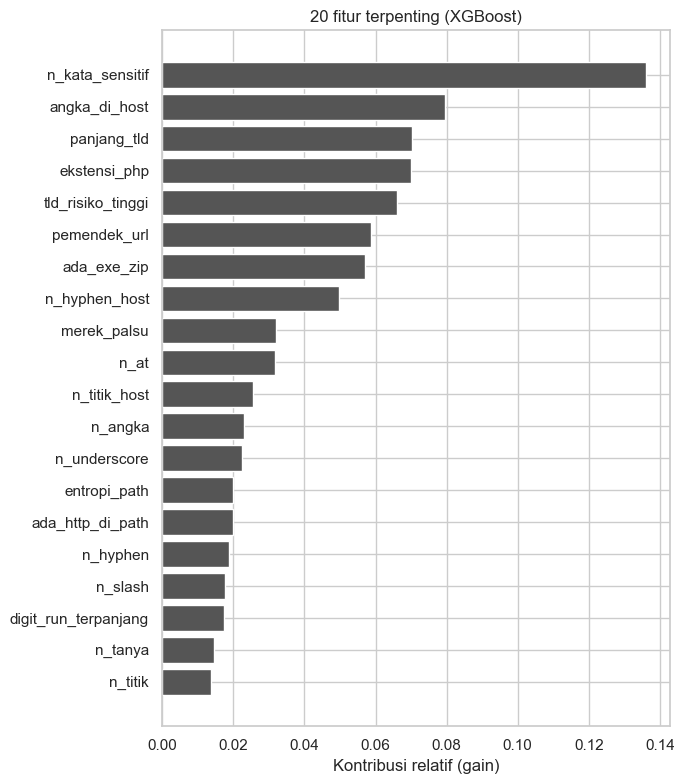

In [19]:
imp = pd.Series(xgb.get_booster().get_score(importance_type="gain")).reindex(NAMA_FITUR).fillna(0).sort_values()
imp = imp / imp.sum()
plt.figure(figsize=(7, 8)); plt.barh(imp.index[-20:], imp.values[-20:], color="#555")
plt.xlabel("Kontribusi relatif (gain)"); plt.title("20 fitur terpenting (XGBoost)")
plt.tight_layout(); plt.savefig(FIG/"08_importance.png", dpi=150); plt.show()

### 11.1 Apa yang sebenarnya dipelajari model teks?
Model TF-IDF tidak punya fitur buatan manusia, jadi kita periksa potongan karakter dengan bobot terbesar. Ini cara mendeteksi apakah model belajar **sifat phishing** atau **artefak data**.

In [20]:
if nama_terbaik.startswith("TFIDF"):
    nm = np.array(tfidf.get_feature_names_out()); w = model_terlatih[nama_terbaik].coef_[0]; o = np.argsort(w)
    tab_ng = pd.DataFrame({"mendorong → PHISHING": [repr(t) for t in nm[o[-25:]][::-1]],
                           "mendorong → LEGITIMATE": [repr(t) for t in nm[o[:25]]]})
    display(tab_ng)

,mendorong → PHISHING,mendorong → LEGITIMATE
0,'mail','htm'
1,'.exe','.com/'
2,'doc','com/'
3,'/gd','om/'
4,'.ex','.htm'
5,'.ru/','.ht'
6,'ru/','.edu/'
7,'/file','.asp'
8,'/im','.com'
9,'php','du/'


**Yang perlu dicermati:** sebagian potongan karakter masuk akal secara keamanan (`login`, `.php`, `wp-`, `.exe`, `pay`, `mail`), tetapi sebagian lain mencerminkan **era dan sumber data**: penanda tahun (`2010`, `2011`, `2015`), TLD institusional (`.edu/`, `.gov/`), dan TLD/platform modern (`.dev`, `.top`). Artinya sebagian skor tinggi model teks berasal dari "kemiripan gaya dengan sumber data", bukan murni karena niat jahat sebuah URL. Ini harus dijelaskan jujur sebagai **keterbatasan** di laporan dan presentasi.

## 12. Menyimpan model + preprocessing sebagai satu `Pipeline`
Aplikasi hanya perlu memberi **URL mentah**; seluruh langkah (normalisasi → fitur → model) ada di dalam satu objek. Ini menjamin preprocessing aplikasi **sama persis** dengan saat pelatihan.

In [21]:
if nama_terbaik.startswith("TFIDF"):
    pipa = Pipeline([("norm", FunctionTransformer(normalisasi_batch)), ("tfidf", tfidf), ("clf", model_terlatih[nama_terbaik])])
else:
    ft = FunctionTransformer(buat_matriks_fitur).fit(["contoh.com"])
    pipa = Pipeline([("fitur", ft), ("clf", model_terlatih[nama_terbaik])])

# --- Uji konsistensi: pipeline (URL mentah) HARUS sama dengan hasil pelatihan (fitur siap pakai) ---
sampel = df.iloc[idx_te].sample(2000, random_state=SEED)
p_pipa = pipa.predict_proba(sampel["url"].tolist())[:, 1]
p_ref = pd.Series(p_te, index=err.index).loc[sampel.index].values
print("Selisih maksimum probabilitas pipeline vs pelatihan:", float(np.abs(p_pipa - p_ref).max()))
assert np.allclose(p_pipa, p_ref, atol=1e-4), "Pipeline tidak konsisten dengan pelatihan!"

joblib.dump(pipa, "models/model_phishing.joblib", compress=3)
meta = {"nama_model": nama_terbaik, "threshold": THRESHOLD, "target_recall_validasi": TARGET_RECALL,
        "metrik_uji": {k: round(float(v), 4) for k, v in hasil_te.items()},
        "jumlah_fitur": len(NAMA_FITUR), "seed": SEED,
        "versi": {"sklearn": sklearn.__version__, "xgboost": xgboost.__version__, "pandas": pd.__version__},
        "ukuran_data": {"latih": int(len(idx_tr)), "validasi": int(len(idx_va)), "uji": int(len(idx_te))}}
Path("models/model_phishing_meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print("Model tersimpan:", Path("models/model_phishing.joblib").stat().st_size // 1024, "KB")
print(json.dumps(meta, indent=2, ensure_ascii=False))

Selisih maksimum probabilitas pipeline vs pelatihan: 0.0
Model tersimpan: 4958 KB
{
  "nama_model": "TFIDF-char + LogReg",
  "threshold": 0.44290197593338215,
  "target_recall_validasi": 0.95,
  "metrik_uji": {
    "accuracy": 0.9538,
    "precision": 0.9067,
    "recall": 0.95,
    "f1": 0.9279,
    "roc_auc": 0.9897,
    "pr_auc": 0.9824
  },
  "jumlah_fitur": 40,
  "seed": 42,
  "versi": {
    "sklearn": "1.7.0",
    "xgboost": "3.3.0",
    "pandas": "2.2.3"
  },
  "ukuran_data": {
    "latih": 371793,
    "validasi": 69603,
    "uji": 55633
  }
}


## 13. Uji fungsi aplikasi (≥ 10 contoh) dan uji input tidak valid
Soal UAS meminta pencatatan **hasil yang diharapkan, hasil aktual, kendala, dan perbaikan**. Uji ini melengkapi (bukan menggantikan) evaluasi pada data uji.

Contoh phishing di bawah adalah **URL simulasi yang saya karang** (tidak mengarah ke situs sungguhan), mengikuti pola umum phishing. Contoh aman adalah situs publik terkenal.

In [22]:
from predictor import prediksi, validasi_input

kasus = [  # (url, harapan, keterangan)
    ("https://www.google.com", "AMAN", "situs populer"),
    ("https://id.wikipedia.org/wiki/Phishing", "AMAN", "halaman ensiklopedia"),
    ("https://github.com/scikit-learn/scikit-learn", "AMAN", "repositori publik"),
    ("https://www.kompas.com/", "AMAN", "situs berita"),
    ("https://www.tokopedia.com/", "AMAN", "marketplace"),
    ("http://192.168.10.5/secure-login/verify-account.php?user=1", "PHISHING", "IP + kata sensitif + .php"),
    ("http://paypal.com.account-verify.tk/signin", "PHISHING", "meniru merek + TLD berisiko"),
    ("http://bca-klikbca.verifikasi-akun.xyz/login.php", "PHISHING", "meniru bank Indonesia"),
    ("https://secure-update-netflix-billing.web.app/login", "PHISHING", "ber-https tetapi meniru merek"),
    ("http://login.microsoftonline.com.secure-docs.cn/owa/?redirect=http://evil.example/steal", "PHISHING", "subdomain menyesatkan + http tertanam"),
    ("http://secure.bank-update.info/@confirm/index.html", "PHISHING", "simbol @ + kata sensitif"),
    ("https://docs.google.com/forms/d/e/1FAIpQLSexample/viewform", "AMAN", "Google Forms sah (kasus sulit: platform yang sering disalahgunakan)"),
]
rows = []
for url, harapan, ket in kasus:
    r = prediksi(url)
    aktual = "PHISHING" if r["status"] == "PHISHING" else ("MENCURIGAKAN" if r["status"] == "MENCURIGAKAN" else "AMAN")
    cocok = (aktual == harapan) or (harapan == "PHISHING" and aktual == "MENCURIGAKAN")
    rows.append({"url": url[:70], "harapan": harapan, "aktual": aktual, "prob_phishing": round(r["probabilitas_phishing"], 3), "sesuai": "✔" if cocok else "✘", "keterangan": ket, "catatan_aplikasi": r.get("catatan_konteks") or "-"})
uji = pd.DataFrame(rows)
display(uji)
print("Sesuai harapan: %d/%d" % ((uji.sesuai == "✔").sum(), len(uji)))
uji.to_csv("reports/uji_fungsi_contoh.csv", index=False)

,url,harapan,aktual,prob_phishing,sesuai,keterangan,catatan_aplikasi
0,https://www.google.com,AMAN,AMAN,0.013,✔,situs populer,-
1,https://id.wikipedia.org/wiki/Phishing,AMAN,AMAN,0.000,✔,halaman ensiklopedia,-
2,https://github.com/scikit-learn/scikit-learn,AMAN,PHISHING,0.532,✘,repositori publik,"Alamat ini berada di layanan umum (github.com) yang dipakai banyak orang, termasuk penipu. ..."
3,https://www.kompas.com/,AMAN,MENCURIGAKAN,0.227,✘,situs berita,-
4,https://www.tokopedia.com/,AMAN,AMAN,0.038,✔,marketplace,-
5,http://192.168.10.5/secure-login/verify-account.php?user=1,PHISHING,PHISHING,1.000,✔,IP + kata sensitif + .php,-
6,http://paypal.com.account-verify.tk/signin,PHISHING,PHISHING,1.000,✔,meniru merek + TLD berisiko,-
7,http://bca-klikbca.verifikasi-akun.xyz/login.php,PHISHING,PHISHING,1.000,✔,meniru bank Indonesia,-
8,https://secure-update-netflix-billing.web.app/login,PHISHING,PHISHING,1.000,✔,ber-https tetapi meniru merek,"Alamat ini berada di layanan umum (web.app) yang dipakai banyak orang, termasuk penipu. Has..."
9,http://login.microsoftonline.com.secure-docs.cn/owa/?redirect=http://e,PHISHING,PHISHING,1.000,✔,subdomain menyesatkan + http tertanam,-


Sesuai harapan: 9/12


In [23]:
tidak_valid = [("", "kosong"), ("   ", "hanya spasi"), ("halo dunia", "bukan URL (ada spasi)"), ("abc", "tanpa titik/domain"),
               ("javascript:alert(1)", "skema berbahaya"), ("file:///etc/passwd", "skema file"), ("ftp2://x.com", "skema tidak didukung"),
               ("http://", "tanpa host"), ("http://exa mple.com", "spasi di domain"), ("http://999.999.999.999/x", "IP tidak valid"),
               ("http://a..com", "titik ganda"), ("https://" + "a"*2100 + ".com", "terlalu panjang"), (None, "None")]
rows = []
for teks, ket in tidak_valid:
    ok, pesan = validasi_input(teks)
    r = prediksi(teks)           # prediksi() tidak boleh crash walau input buruk
    rows.append({"input": (repr(teks)[:40]), "keterangan": ket, "ditolak": "✔" if (not ok and not r["valid"]) else "✘", "pesan": pesan})
display(pd.DataFrame(rows))
pd.DataFrame(rows).to_csv("reports/uji_input_tidak_valid.csv", index=False)

# input valid tak biasa: harus diterima, bukan ditolak
for t in ["EXAMPLE.COM/Path", "https://xn--e1afmkfd.xn--p1ai/", "http://[2001:db8::1]/login", "contoh.co.id/a?b=c#frag"]:
    print(f"{t:<40} valid = {validasi_input(t)[0]}")

,input,keterangan,ditolak,pesan
0,'',kosong,✔,URL masih kosong. Tempel tautan yang ingin diperiksa.
1,' ',hanya spasi,✔,URL masih kosong. Tempel tautan yang ingin diperiksa.
2,'halo dunia',bukan URL (ada spasi),✔,URL tidak boleh mengandung spasi. Pastikan hanya satu tautan yang ditempel.
3,'abc',tanpa titik/domain,✔,"Domain tidak lengkap (tidak ada titik, mis. 'contoh.com')."
4,'javascript:alert(1)',skema berbahaya,✔,Hanya tautan web (http/https) yang dapat diperiksa.
5,'file:///etc/passwd',skema file,✔,Hanya tautan web (http/https) yang dapat diperiksa.
6,'ftp2://x.com',skema tidak didukung,✔,Skema 'ftp2://' tidak didukung. Gunakan tautan http atau https.
7,'http://',tanpa host,✔,Bagian alamat situs (domain) tidak valid.
8,'http://exa mple.com',spasi di domain,✔,URL tidak boleh mengandung spasi. Pastikan hanya satu tautan yang ditempel.
9,'http://999.999.999.999/x',IP tidak valid,✔,Alamat IP tidak valid.


EXAMPLE.COM/Path                         valid = True
https://xn--e1afmkfd.xn--p1ai/           valid = True
http://[2001:db8::1]/login               valid = True
contoh.co.id/a?b=c#frag                  valid = True


## 14. Ringkasan hasil

In [24]:
print(f"Model final       : {nama_terbaik}")
print(f"Threshold         : {THRESHOLD:.3f} (target recall validasi {TARGET_RECALL:.0%})")
print(f"Data uji          : precision {hasil_te['precision']:.3f} | recall {hasil_te['recall']:.3f} | F1 {hasil_te['f1']:.3f} | accuracy {hasil_te['accuracy']:.3f} | PR-AUC {hasil_te['pr_auc']:.3f}")
print(f"Kesalahan         : FP={fp:,} ({fp/(tn+fp):.1%} dari legit)  FN={fn:,} ({fn/(fn+tp):.1%} dari phishing)")
print(f"Ablation          : F1 dengan https/www {abl.iloc[0,0]:.3f} vs tanpa {abl.iloc[0,1]:.3f}  → jalan pintas membuat skor tampak {abl.iloc[0,0]-abl.iloc[0,1]:+.2f} lebih baik")
print(f"Uji fungsi        : {(uji.sesuai=='✔').sum()}/{len(uji)} sesuai harapan")

Model final       : TFIDF-char + LogReg
Threshold         : 0.443 (target recall validasi 95%)
Data uji          : precision 0.907 | recall 0.950 | F1 0.928 | accuracy 0.954 | PR-AUC 0.982
Kesalahan         : FP=1,701 (4.4% dari legit)  FN=870 (5.0% dari phishing)
Ablation          : F1 dengan https/www 0.958 vs tanpa 0.762  → jalan pintas membuat skor tampak +0.20 lebih baik
Uji fungsi        : 9/12 sesuai harapan


### Keterbatasan yang wajib ditulis di laporan
1. **Hanya melihat teks URL.** Isi halaman, usia domain, sertifikat, dan reputasi IP tidak dipakai. Phishing dengan URL yang tampak rapi (domain baru bersih) dapat lolos.
2. **Sumber dan era data berbeda.** Legitimate hanya berasal dari Dataset 1 (lama), phishing modern hanya dari Dataset 2. Model bisa belajar "gaya sumber" selain "sifat phishing" (lihat 11.1 dan 9.1).
3. **Platform sah yang sering disalahgunakan** (Google Docs/Forms, GitHub, Weebly, dst.) berisiko dianggap phishing (false positive) atau sebaliknya lolos (false negative). Aplikasi memberi catatan konteks pada kasus ini.
4. **Pergeseran waktu (concept drift).** Pola phishing berubah cepat; model perlu dilatih ulang berkala dengan data baru.
5. **Tidak ada uji pada URL penyerang yang sengaja menghindari model** (adversarial). Skor tinggi pada data uji tidak menjamin ketahanan.